# Five-minute crypto strategy pilot

## tl;dr

- At 20 bps, 0 of 18 configurations had positive January-September 2026 net returns. Across all four partitions, 72 of 72 primary case-period results were negative. Every case is retained; this is descriptive, not a corrected discovery test.

- Momentum L15m / R60m: gross -26.67%; net at 5 bps -98.96%; at 20 bps retained only 2.86e-08 of initial capital (net return rounds to -100%). The selected 2024 control was already negative after costs.

- Reversal L15m / R60m: gross 33.53%; net at 5 bps -98.11%; at 20 bps retained only 5.22e-08 of initial capital (net return rounds to -100%). The selected 2024 control was already negative after costs.

- Five-minute sampling is a new measurement granularity, not new untouched market history. Every period in this follow-up, including 2026, is exploratory/retrospective. Shorter horizons do not lower costs, and OHLCV closes do not demonstrate executable microstructure profits.

## Context & Methods

Actual 5m bars, 18 declared momentum/reversal configurations, 5/15/30-minute trailing signals, 5/15/60-minute calendar schedules. One historically selected control per family uses 2024 net daily Sharpe at 20 bps, turnover then ID for ties. **Every period is exploratory/retrospective, including 2026**; changing granularity does not recreate an untouched holdout.

### Key Assumptions

Theoretical spot shorts; gross-one rank/demean/full-L1 targets; averaged ties and cash for constant signals. Cost is all-in one-way bps times full-L1 changes, including entry/liquidation. Completed endpoint signals with one-bar lag; lag two adds five minutes. No funding/borrow, drift turnover, capacity, or guaranteed close fills. Daily compounded returns use 365-day annualization; minute samples are not independent daily returns.

### 1. Load completed hash-verified research

No cell downloads prices or changes selections. Inputs are the completed experiment/protocol receipts and cached audited sources.

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'outputs/run_manifest.json').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from crypto_intraday_5m.reporting import (load_outputs,primary,label,reconcile_selected,plot_selection,plot_periods,plot_equity,plot_costs,plot_turnover,historical_break_even)
d=load_outputs(ROOT)
print('Classification: entire pilot exploratory/retrospective; no fresh holdout.')
print('Grid:',d['experiments'].strategy_id.nunique(),'configurations;',len(d['experiments']),'configuration-period-scenario rows.')
spec_table=pd.DataFrame(d['specs'])
display(spec_table[['strategy_id','lookback_minutes','rebalance_minutes','role','validation_sharpe']].round(5))

Classification: entire pilot exploratory/retrospective; no fresh holdout.
Grid: 18 configurations; 504 configuration-period-scenario rows.


,strategy_id,lookback_minutes,rebalance_minutes,role,validation_sharpe
0,momentum_m015_r060,15,60,negative_control,-88.41151
1,reversal_m015_r060,15,60,negative_control,-94.16908


## Data

### 2. Inspect the actual five-minute audit

Endpoint = bar-open plus five minutes. Source timestamp units switch in January 2025. The March 24, 2023 bridge is 11:25 to 14:05 UTC (160 minutes), with no interior valuation/execution or filled missing prices. Raw partial/zero-trade bars remain source evidence. The hourly comparison retains three monthly-close and 134 volume discrepancies, all in December 2021 warm-up, and none in evaluated January 2022-September 2026. Verified daily five-minute closes match hourly at the three discrepant endpoints; no source values are replaced. No evaluated return or max-30-minute lookback uses those early-December endpoints. Price/volume reconciliation is a data check, not a portfolio-equivalence claim.

In [2]:
audit=d['audit']
display(pd.DataFrame([{'item':k,'value':audit.get(k)} for k in ['status','rows','expected_rows','panel_rows','missing_count','duplicate_count','normalized_parquet_sha256']]))
print('Hourly data reconciliation (scalar receipt fields; complete receipt retained):')
display(pd.DataFrame([{'item':k,'value':str(v)} for k,v in d['reconciliation'].items() if not isinstance(v,(dict,list))]))

,item,value
0,status,pass_with_documented_exceptions
1,rows,4066432
2,expected_rows,4066560
3,panel_rows,508320
4,missing_count,128
5,duplicate_count,0
6,normalized_parquet_sha256,cc253b0782f16dbdafcae7889a62806ae3ea53f456bd74...


Hourly data reconciliation (scalar receipt fields; complete receipt retained):


,item,value
0,comparison_end,2026-10-01T00:00:00+00:00
1,comparison_start,2021-12-01T01:00:00+00:00
2,complete_volume_cells_compared,338864
3,evaluation_price_cells_compared,332920
4,evaluation_price_exact_mismatch_count,0
5,evaluation_source_discrepancy_requires_review,False
6,evaluation_volume_mismatch_count,0
7,generated_utc,2026-10-06T17:21:07.805882+00:00
8,hourly_endpoints,42359
9,incomplete_five_minute_volume_cells,8


### 3. Independently reconcile selected holdings and accounting

This calculation does not call the simulator: it uses cached observed close-to-close returns, removes only the declared halt interior, recomputes held-weight P&L, full-L1 turnover, cash entry/final liquidation, cost, compounded equity, daily volatility and Sharpe. The 2026 window must contain 78,624 five-minute returns spanning 393,120 minutes and 273 complete days.

In [3]:
reconciled=reconcile_selected(ROOT,d)
display(reconciled.round(8))
assert len(reconciled)==8
print('All selected model/period primary reconciliations passed.')

,strategy_id,split,observations,daily_observations,total_return,full_l1_turnover,status
0,momentum_m015_r060,development,210209,730,-1.0,22732.770833,reconciled
1,momentum_m015_r060,retrospective,105120,365,-1.0,11409.562500,reconciled
2,momentum_m015_r060,retrospective_2026,78624,273,-1.0,8517.495833,reconciled
3,momentum_m015_r060,validation,105408,366,-1.0,11416.887500,reconciled
4,reversal_m015_r060,development,210209,730,-1.0,22732.770833,reconciled
5,reversal_m015_r060,retrospective,105120,365,-1.0,11409.562500,reconciled
6,reversal_m015_r060,retrospective_2026,78624,273,-1.0,8517.495833,reconciled
7,reversal_m015_r060,validation,105408,366,-1.0,11416.887500,reconciled


All selected model/period primary reconciliations passed.


## Results

### 4. All declared 2024 configurations: gross versus cost-aware

Asterisks mark the historically selected controls. Gross and net performance use the same signals; no 2025/2026 observation determines selection.

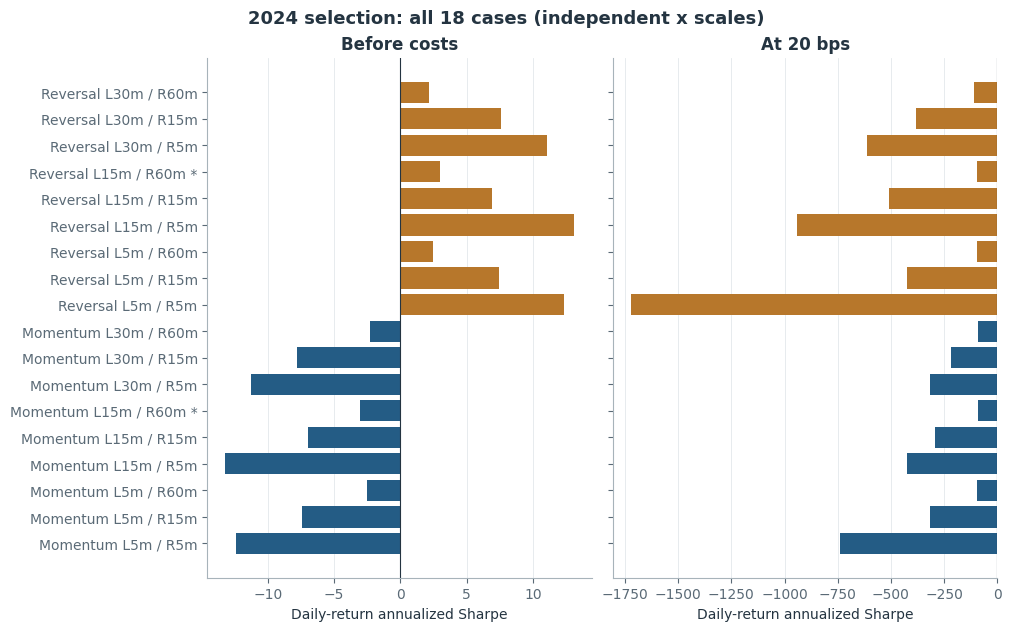

,strategy_id,gross_total_return,total_return,gross_sharpe,sharpe,total_turnover
11,momentum_m005_r005,-0.97346,-1.0,-12.42297,-738.99483,139159.81250
25,momentum_m005_r015,-0.85743,-1.0,-7.46112,-315.61239,45509.25833
39,momentum_m005_r060,-0.46381,-1.0,-2.54348,-96.75605,11422.84583
53,momentum_m015_r005,-0.96647,-1.0,-13.25392,-426.22700,83218.06250
67,momentum_m015_r015,-0.84402,-1.0,-6.95031,-290.70695,46402.89583
81,momentum_m015_r060,-0.54669,-1.0,-3.03365,-88.41151,11416.88750
95,momentum_m030_r005,-0.93836,-1.0,-11.25792,-318.28977,61573.88750
109,momentum_m030_r015,-0.85734,-1.0,-7.79784,-215.63676,33299.36667
123,momentum_m030_r060,-0.42220,-1.0,-2.30430,-91.58093,11438.04583
137,reversal_m005_r005,33.92289,-1.0,12.34197,-1719.47104,139159.81250


In [4]:
fig=plot_selection(d['experiments'],d['selection'])
plt.show()
g=primary(d['experiments']);validation=g.loc[g.split.eq('validation')]
display(validation[['strategy_id','gross_total_return','total_return','gross_sharpe','sharpe','total_turnover']].round(5))

### 5. Every case across all retrospective partitions

All 18 cases are retained, not just the selected two. The matrix shows terminal log10 capital, preserving severe-loss distinctions hidden by -100% rounding: -10 means only 10^-10 of initial capital remains. Periods have unequal durations: two years, one year, one year, nine months. Rounded -100% paths may remain mathematically positive but economically wiped out; inspect the exact CSV and log equity rather than treating them as identical or missing.

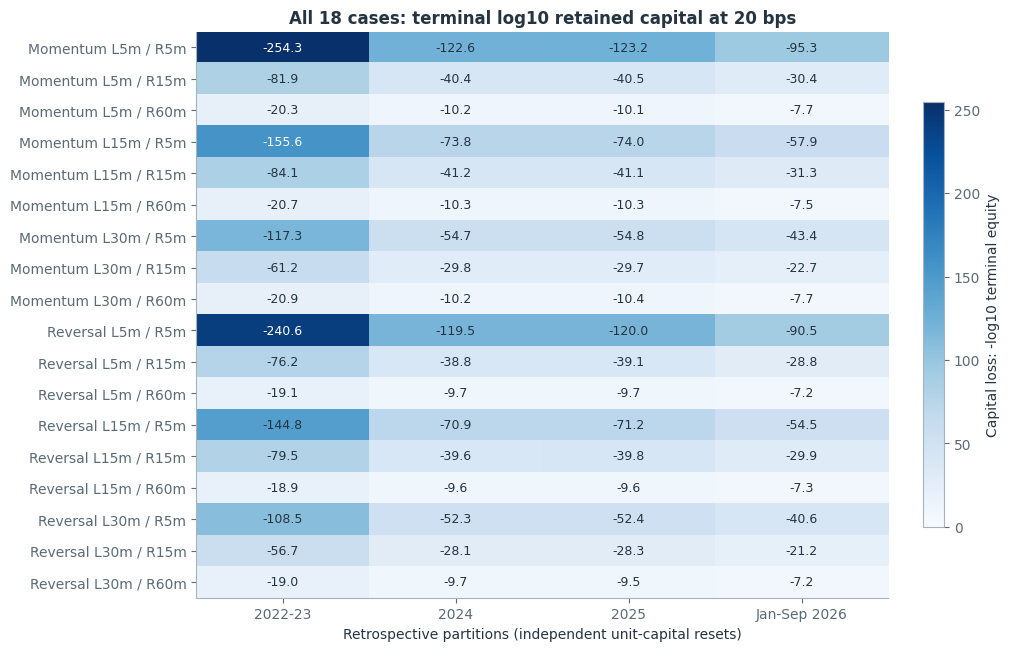

In [5]:
fig=plot_periods(d['experiments'])
plt.show()

### 6. Selected 2026 paths on a logarithmic scale

The graph uses stored log wealth divided by ln(10), preserving finite wealth even if displayed floating-point equity underflows to zero. Underflow is not bankruptcy; invalid interval returns at or below -100% are rejected, not clipped. These are January-September retrospective paths, not a fresh holdout.

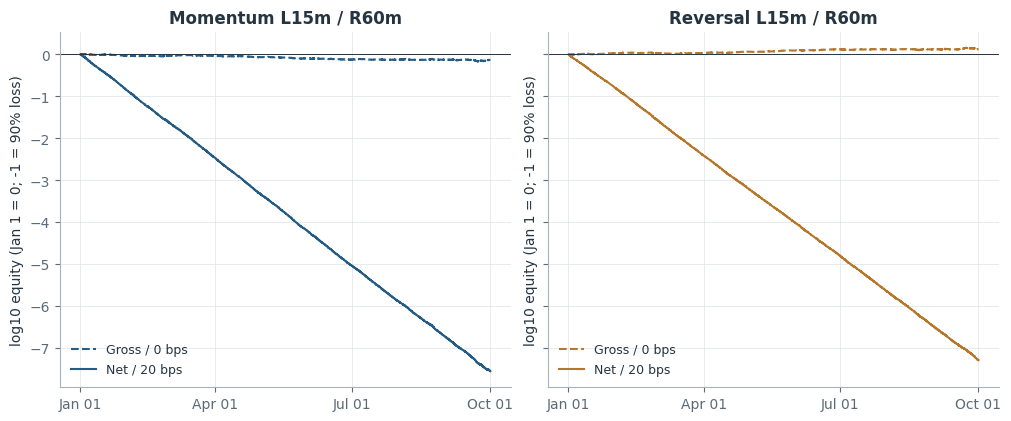

,strategy_id,gross_total_return,total_return,annual_volatility,sharpe,max_drawdown
333,momentum_m015_r060,-0.266689,-1.0,0.183088,-122.793824,1.0
459,reversal_m015_r060,0.335301,-1.0,0.138915,-156.462945,1.0


In [6]:
fig=plot_equity(d['returns'])
plt.show()
ids=[x['strategy_id'] for x in d['specs']]
selected=g.loc[g.split.eq('retrospective_2026')&g.strategy_id.isin(ids)]
display(selected[['strategy_id','gross_total_return','total_return','annual_volatility','sharpe','max_drawdown']].round(6))

### 7. Annualization, exposure and BTC regression

CAGR and arithmetic annualized return are transformations of nine-month evidence, not twelve-month observations. BTC alpha/beta come from daily OLS with intercept and HAC(7) 95% intervals. Missing/undefined quantities remain missing, never zero.

In [7]:
annual_columns=[c for c in ['strategy_id','cagr','annual_return','alpha_annual','alpha_ci_low','alpha_ci_high','beta'] if c in selected]
exposure_columns=[c for c in ['strategy_id','mean_gross_exposure','mean_net_exposure','fraction_flat','n_days','n_minutes','terminal_log_equity','equity_underflow_count'] if c in selected]
display(selected[annual_columns].round(6))
display(selected[exposure_columns].round(6))

,strategy_id,cagr,annual_return,alpha_annual,alpha_ci_low,alpha_ci_high,beta
333,momentum_m015_r060,-1.0,-22.482060,-22.482356,-22.888830,-22.075881,0.006912
459,reversal_m015_r060,-1.0,-21.735035,-21.734279,-22.043361,-21.425197,-0.017693


,strategy_id,mean_gross_exposure,mean_net_exposure,fraction_flat,n_days,n_minutes,terminal_log_equity,equity_underflow_count
333,momentum_m015_r060,1,0.0,0,273,393120,-17.369689,0
459,reversal_m015_r060,1,-0.0,0,273,393120,-16.768902,0


### 8. Cost and one additional five-minute execution bar

Primary cost remains 20 bps even at a shorter time scale. Scenarios are assumptions, not uncertainty intervals. The five-bps total scenario is below the course's assumed seven-bps commission alone.

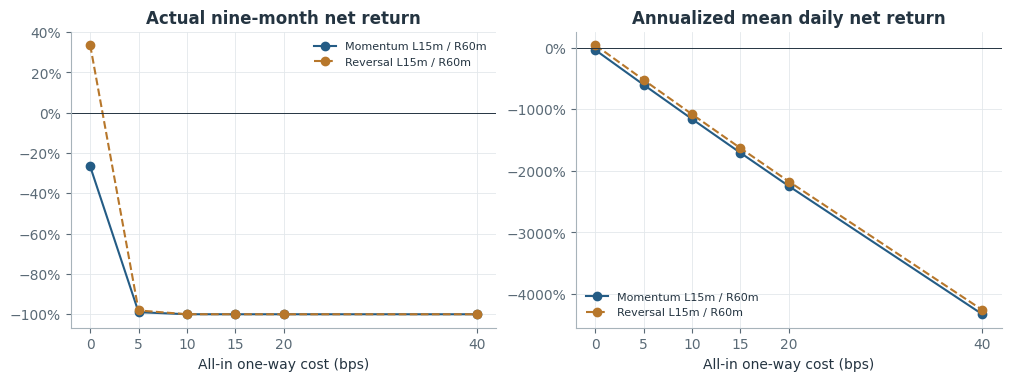

,strategy_id,execution_lag,total_return,sharpe,total_turnover
333,momentum_m015_r060,1,-1.0,-122.793824,8517.495833
335,momentum_m015_r060,2,-1.0,-119.517356,8518.495833
459,reversal_m015_r060,1,-1.0,-156.462945,8517.495833
461,reversal_m015_r060,2,-1.0,-154.807945,8518.495833


In [8]:
fig=plot_costs(d['experiments'],d['selection'])
plt.show()
lag=d['experiments'].loc[d['experiments'].split.eq('retrospective_2026')&d['experiments'].strategy_id.isin(ids)&d['experiments'].cost_bps.eq(20)]
display(lag[['strategy_id','execution_lag','total_return','sharpe','total_turnover']].sort_values(['strategy_id','execution_lag']).round(6))

### 9. Post-hoc historical zero-profit cost

This derivative calculation does not select or tune a strategy. It solves the compounded saved-path return equation for an all-in one-way cost threshold. It is historical, not a confidence interval or a future tradability promise. A threshold below the course commission alone cannot justify lowering primary costs.

In [9]:
derived=historical_break_even(d)
display(pd.DataFrame([{'strategy_id':k,'break_even_cost_bps':v['cost_bps']} for k,v in derived.items()]))
assert abs(derived['reversal_m015_r060']['cost_bps']-0.33949153642324725)<1e-10
assert derived['momentum_m015_r060']['cost_bps'] is None
print('Reversal break-even about 0.34 bps; momentum has no nonnegative threshold.')

,strategy_id,break_even_cost_bps
0,momentum_m015_r060,NaN
1,reversal_m015_r060,0.339492


Reversal break-even about 0.34 bps; momentum has no nonnegative threshold.


### 10. Full-L1 turnover for all cases

Turnover/day is total full-L1 change divided by 273 days, not trade count or gross exposure. Sum of interval costs reconciles to rate times turnover, but compounded gross/net total-return differences are not an additive cost waterfall.

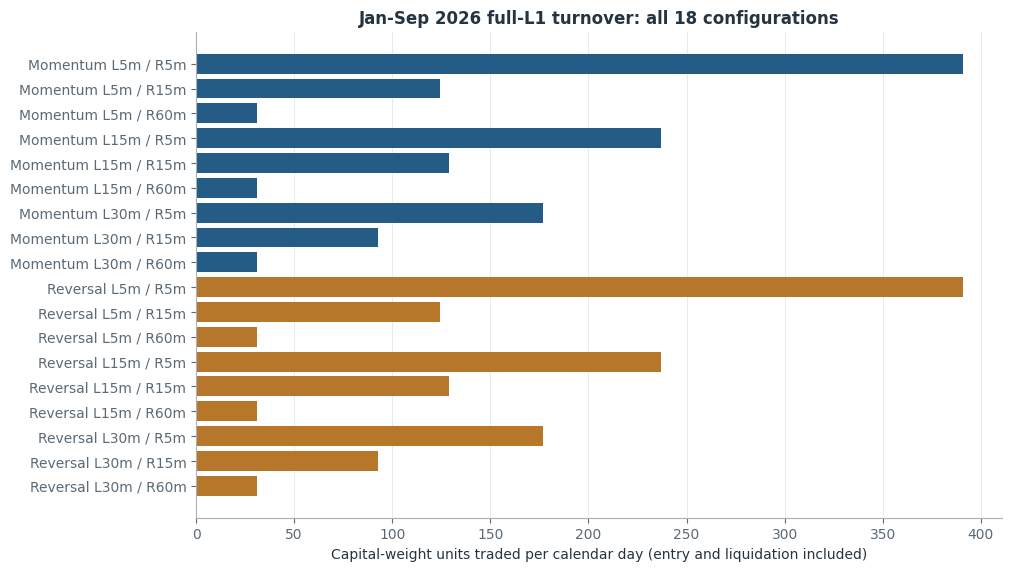

,strategy_id,gross_total_return,total_return,sharpe,turnover_per_day
263,momentum_m005_r005,-0.99575,-1.0,-879.09961,391.11012
277,momentum_m005_r015,-0.84193,-1.0,-421.66224,124.52154
291,momentum_m005_r060,-0.42855,-1.0,-135.58936,31.26569
305,momentum_m015_r005,-0.97858,-1.0,-420.90923,236.79594
319,momentum_m015_r015,-0.78647,-1.0,-340.05063,128.82929
333,momentum_m015_r060,-0.26669,-1.0,-122.79382,31.19962
347,momentum_m030_r005,-0.96204,-1.0,-286.67448,177.07730
361,momentum_m030_r015,-0.81056,-1.0,-247.96207,92.47782
375,momentum_m030_r060,-0.41319,-1.0,-123.86062,31.28092
389,reversal_m005_r005,229.03730,-1.0,-1822.55726,391.11012


In [10]:
fig=plot_turnover(d['experiments'])
plt.show()
all_2026=g.loc[g.split.eq('retrospective_2026')].copy()
all_2026['turnover_per_day']=all_2026.total_turnover/273
display(all_2026[['strategy_id','gross_total_return','total_return','sharpe','turnover_per_day']].round(5))

## Takeaways

- At 20 bps, 0 of 18 configurations had positive January-September 2026 net returns. Across all four partitions, 72 of 72 primary case-period results were negative. Every case is retained; this is descriptive, not a corrected discovery test.

- Momentum L15m / R60m: gross -26.67%; net at 5 bps -98.96%; at 20 bps retained only 2.86e-08 of initial capital (net return rounds to -100%). The selected 2024 control was already negative after costs.

- Reversal L15m / R60m: gross 33.53%; net at 5 bps -98.11%; at 20 bps retained only 5.22e-08 of initial capital (net return rounds to -100%). The selected 2024 control was already negative after costs.

- Five-minute sampling is a new measurement granularity, not new untouched market history. Every period in this follow-up, including 2026, is exploratory/retrospective. Shorter horizons do not lower costs, and OHLCV closes do not demonstrate executable microstructure profits.

The fixed survivor universe, theoretical shorts, absent financing/margin/capacity, idealized closes and omitted weight drift limit tradability. OHLCV is not bid/ask or order-book evidence. No live orders, publication, or scheduled monitoring.

## Sources and reproduction

- [Binance archives](https://github.com/binance/binance-public-data)
- [Binance dataset terms](https://github.com/binance/binance-public-data/blob/master/TERMS_AND_CONDITIONS.md)
- [Official 2023 incident](https://www.binance.com/en/blog/from-our-ceo/6789340645608890113)
- Course source: `/Users/cosdis/Downloads/quant_course/ClassProject.docx`

Binance data and derived figures/results are attributed to Binance under the stated CC BY-NC-SA 4.0 non-commercial educational/personal non-production terms. Original and extended hourly projects/ZIPs remain unchanged.

Regenerate cached artifacts: `python -m crypto_intraday_5m report`. Tests: `python -m pytest -q`. Use `/Users/cosdis/.venvs/myenv/bin/python`.